C:\Users\Sairam\Anaconda3\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Normal training samples: 5923
Normal testing samples: 980

Autoencoder Summary:
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 784)]             0         
                                                                 
 sequential (Sequential)     (None, 32)                110816    
                                                                 
 sequential_1 (Sequential)   (None, 784)               111568    
                                                                 
Total params: 222384 (868.69 KB)
Trainable params: 222384 (868.69 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/20
38/38 [==============================] - 23s 43ms/step - loss: 0.1085 - mae: 0.2295 - val_loss: 0.0614 - val_mae: 0.1294


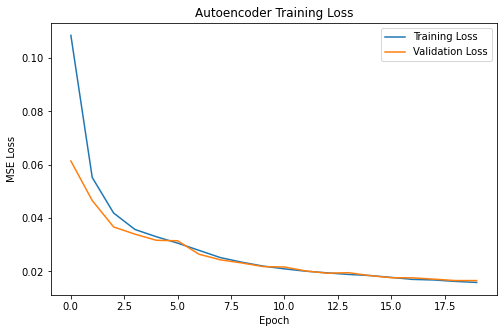


Anomaly Threshold: 0.03233130145817993
Anomaly samples: 1135

========== RESULTS ==========
Normal samples incorrectly classified: 49
Anomalies detected: 1133
Anomaly Detection Rate: 99.82 %
False Positive Rate: 5.0 %


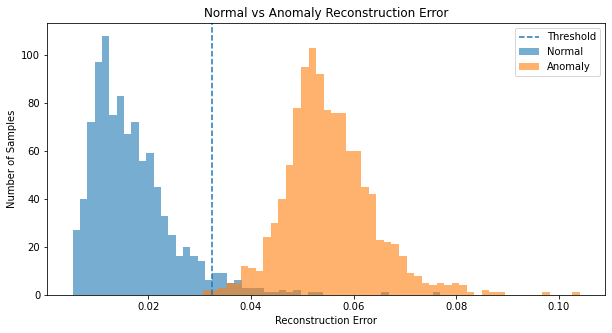

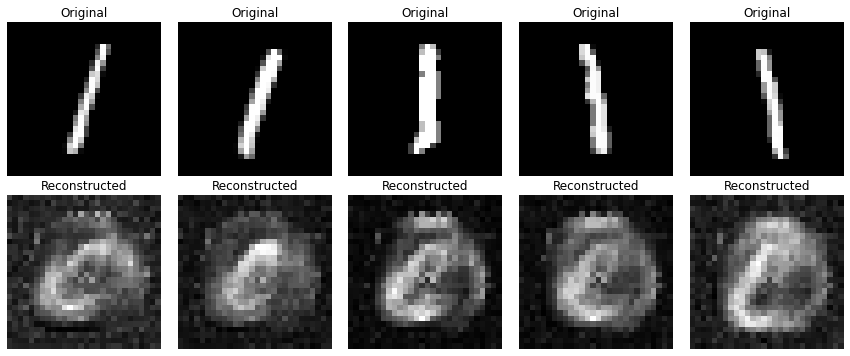

In [1]:
# ==========================================================
# PRACTICAL 4: ANOMALY DETECTION USING AUTOENCODER
# Dataset: MNIST
# Normal Class: 0
# Anomaly Class: 1
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ----------------------------------------------------------
# 1. Load Dataset
# ----------------------------------------------------------

(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# ----------------------------------------------------------
# 2. Normalize Data
# ----------------------------------------------------------

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# ----------------------------------------------------------
# 3. Select Normal Data (Digit 0)
# ----------------------------------------------------------

normal_class = 0

x_train_normal = x_train[y_train == normal_class]
x_test_normal = x_test[y_test == normal_class]

print("Normal training samples:",
      len(x_train_normal))

print("Normal testing samples:",
      len(x_test_normal))

# ----------------------------------------------------------
# 4. Flatten Images
# ----------------------------------------------------------

x_train_normal = x_train_normal.reshape(
    len(x_train_normal), 784
)

x_test_normal = x_test_normal.reshape(
    len(x_test_normal), 784
)

# ----------------------------------------------------------
# 5. Build Encoder
# ----------------------------------------------------------

input_dim = 784
latent_dim = 32

encoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(latent_dim, activation="relu")
])

# ----------------------------------------------------------
# 6. Build Decoder
# ----------------------------------------------------------

decoder = models.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(input_dim, activation="sigmoid")
])

# ----------------------------------------------------------
# 7. Combine Encoder + Decoder
# ----------------------------------------------------------

autoencoder_input = layers.Input(
    shape=(input_dim,)
)

encoded = encoder(autoencoder_input)
decoded = decoder(encoded)

autoencoder = models.Model(
    autoencoder_input,
    decoded
)

# ----------------------------------------------------------
# 8. Compile Model
# ----------------------------------------------------------

autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("\nAutoencoder Summary:")
autoencoder.summary()

# ----------------------------------------------------------
# 9. Train Autoencoder
# ----------------------------------------------------------

history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    shuffle=True
)

# ----------------------------------------------------------
# 10. Plot Training Loss
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

# ----------------------------------------------------------
# 11. Reconstruct Normal Data
# ----------------------------------------------------------

normal_reconstructed = autoencoder.predict(
    x_test_normal,
    verbose=0
)

# ----------------------------------------------------------
# 12. Calculate Normal Reconstruction Error
# ----------------------------------------------------------

normal_errors = np.mean(
    np.square(
        x_test_normal - normal_reconstructed
    ),
    axis=1
)

# ----------------------------------------------------------
# 13. Calculate Threshold
# ----------------------------------------------------------

threshold = np.percentile(
    normal_errors,
    95
)

print("\nAnomaly Threshold:",
      threshold)

# ----------------------------------------------------------
# 14. Prepare Anomaly Data (Digit 1)
# ----------------------------------------------------------

anomaly_class = 1

x_test_anomaly = x_test[
    y_test == anomaly_class
]

x_test_anomaly = x_test_anomaly.reshape(
    len(x_test_anomaly), 784
)

print("Anomaly samples:",
      len(x_test_anomaly))

# ----------------------------------------------------------
# 15. Reconstruct Anomaly Data
# ----------------------------------------------------------

anomaly_reconstructed = autoencoder.predict(
    x_test_anomaly,
    verbose=0
)

# ----------------------------------------------------------
# 16. Calculate Anomaly Error
# ----------------------------------------------------------

anomaly_errors = np.mean(
    np.square(
        x_test_anomaly - anomaly_reconstructed
    ),
    axis=1
)

# ----------------------------------------------------------
# 17. Detect Anomalies
# ----------------------------------------------------------

normal_predictions = normal_errors > threshold

anomaly_predictions = anomaly_errors > threshold

# ----------------------------------------------------------
# 18. Calculate Results
# ----------------------------------------------------------

normal_false_positive = np.sum(
    normal_predictions
)

anomaly_detected = np.sum(
    anomaly_predictions
)

normal_detection_rate = (
    normal_false_positive /
    len(normal_predictions)
) * 100

anomaly_detection_rate = (
    anomaly_detected /
    len(anomaly_predictions)
) * 100

print("\n========== RESULTS ==========")

print(
    "Normal samples incorrectly classified:",
    normal_false_positive
)

print(
    "Anomalies detected:",
    anomaly_detected
)

print(
    "Anomaly Detection Rate:",
    round(anomaly_detection_rate, 2),
    "%"
)

print(
    "False Positive Rate:",
    round(normal_detection_rate, 2),
    "%"
)

# ----------------------------------------------------------
# 19. Plot Reconstruction Error
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    normal_errors,
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    anomaly_errors,
    bins=50,
    alpha=0.6,
    label="Anomaly"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Samples")

plt.title(
    "Normal vs Anomaly Reconstruction Error"
)

plt.legend()
plt.show()

# ----------------------------------------------------------
# 20. Display Anomaly Images
# ----------------------------------------------------------

n = 5

plt.figure(figsize=(12, 5))

for i in range(n):

    # Original image
    plt.subplot(2, n, i + 1)

    plt.imshow(
        x_test_anomaly[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, i + 1 + n)

    plt.imshow(
        anomaly_reconstructed[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()